In [18]:
#activate pytorch_amd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from diffusers import UNet2DModel
import matplotlib.pyplot as plt
from torch.utils.data import Subset
import torch.nn.functional as F
import torch_directml

In [19]:
device = torch_directml.device(1)
print(f"Using device: {device}")

Using device: privateuseone:1


In [20]:
sigma_q = 1
batch_size = 128
transform_pipeline = transforms.Compose([
    transforms.ToTensor(),               
    transforms.Normalize((0.5,), (0.5,)) #rescale to [-1.0, 1.0]
])
train_dataset = torchvision.datasets.MNIST(
    root='./data', 
    train=True,        
    download=True,       
    transform=transform_pipeline 
)

train_loader = torch.utils.data.DataLoader(
    train_dataset, 
    batch_size=batch_size,       
    shuffle=True,
    num_workers=4,        
    pin_memory=True
)

# take 1000 subset to test 
mini_dataset = Subset(train_dataset, range(30000))

# test loader
mini_train_loader = torch.utils.data.DataLoader(
    mini_dataset,
    batch_size=batch_size,
    shuffle=True
)

In [ ]:
# pic extraction
images, labels = next(iter(train_loader))

In [21]:
#U-Net untrained (for v1 use 32,64,64 and sigma_q=1, for others - 64,128,256)
model = UNet2DModel(
    sample_size=28,  
    in_channels=1,   
    out_channels=1,  
    layers_per_block=2, 
    block_out_channels=(64,128,256), 
    down_block_types=("DownBlock2D", "AttnDownBlock2D", "DownBlock2D"),
    up_block_types=("UpBlock2D", "AttnUpBlock2D", "UpBlock2D")
)

In [ ]:
optimizer = optim.Adam(model.parameters(), lr=1e-3)
epochs = 50 


print("Starting Training...")

model = model.to(device)
first_weight_device = next(model.parameters()).device
print(f"The U-Net is currently sitting on: {first_weight_device}")

model.train() 

for epoch in range(epochs):
    total_loss = 0
    
    for batch_images, _ in train_loader:
        
        optimizer.zero_grad()
        batch_images = batch_images.to(device) 
        t_math = torch.rand(batch_images.shape[0], 1, 1, 1, device=device)
        noise = torch.randn_like(batch_images)
        # Calculate your Brownian standard deviation
        std = torch.sqrt(t_math) * sigma_q
        # Create the massive noisy image
        x_t = batch_images + noise * std

        noise_pred = model(x_t, t_math.squeeze() * 1000).sample
        loss = F.mse_loss(noise_pred, noise*std )
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        

    avg_loss = total_loss / len(train_loader)
    print(f"Epoch {epoch+1} | Average Loss: {avg_loss:.4f}")

In [22]:
#for pretrained models
ckpt = torch.load("mnist_diffusion_v40.pt", map_location=device)
model.load_state_dict(ckpt)
model = model.to(device)
model.eval()


C:\Users\ankul\AppData\Local\Temp\ipykernel_20492\179571882.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load("mnist_diffusion_v40.pt", map_location=devi

UNet2DModel(
  (conv_in): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (time_proj): Timesteps()
  (time_embedding): TimestepEmbedding(
    (linear_1): LoRACompatibleLinear(in_features=64, out_features=256, bias=True)
    (act): SiLU()
    (linear_2): LoRACompatibleLinear(in_features=256, out_features=256, bias=True)
  )
  (down_blocks): ModuleList(
    (0): DownBlock2D(
      (resnets): ModuleList(
        (0-1): 2 x ResnetBlock2D(
          (norm1): GroupNorm(32, 64, eps=1e-05, affine=True)
          (conv1): LoRACompatibleConv(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (time_emb_proj): LoRACompatibleLinear(in_features=256, out_features=64, bias=True)
          (norm2): GroupNorm(32, 64, eps=1e-05, affine=True)
          (dropout): Dropout(p=0.0, inplace=False)
          (conv2): LoRACompatibleConv(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (nonlinearity): SiLU()
        )
      )
      (downsamplers): ModuleLis

### DDIM Reverse Sampling

In [27]:
optimizer = optim.Adam(model.parameters(), lr=1e-4)
epochs = 40 
dt = 0.001
model = model.to(device)
#first_weight_device = next(model.parameters()).device
#print(f"the U-Net is on: {first_weight_device}")

model.train() 

for epoch in range(epochs):
    total_loss = 0
    
    for batch_images, _ in train_loader:
        
        optimizer.zero_grad()
        batch_images = batch_images.to(device) 
        t_math = torch.rand(batch_images.shape[0], 1, 1, 1, device=device)
        noise = torch.randn_like(batch_images)
        noise1 = torch.randn_like(batch_images)
        std = torch.sqrt(t_math) * sigma_q
        x_t = batch_images + noise * std
        x_t1 = x_t + noise1 * np.sqrt(dt) * sigma_q

        mu_t = model(x_t1, t_math.squeeze() + dt).sample
        loss = F.mse_loss(mu_t, x_t)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        

    avg_loss = total_loss / len(train_loader)
    print(f"Epoch {epoch+1} | Average Loss: {avg_loss:.4f}")

Starting reverse diffusion...
Generation complete! Final shape: torch.Size([16, 1, 28, 28])


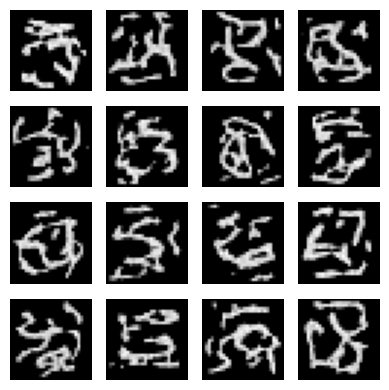

In [28]:
x_clean = (x + 1) / 2

fig, axes = plt.subplots(4, 4, figsize=(4, 4))

for i, ax in enumerate(axes.flatten()):
    img = torch.clamp(x[i], 0.0, 1.0).permute(1, 2, 0).cpu().numpy()
    
    ax.imshow(img, cmap='gray')
    ax.axis('off') 

plt.tight_layout()
plt.show()

In [ ]:
torch.save(model.state_dict(), "mnist_diffusion_v15.pt") #15 epochs

In [ ]:
torch.save(model.state_dict(), "mnist_diffusion_v40.pt") #40 epochs

In [ ]:
torch.save(model.state_dict(), "mnist_diffusion_v40_2.pt") #40 epochs sigma 2

In [ ]:
torch.save(model.state_dict(), "mnist_diffusion_v50_10.pt") #50 epochs sigma 10